# Clasificador

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
X = np.array([
    [1.0, 1.0],
    [1.5, 1.8],
    [2.0, 1.3],
    [2.2, 2.0],
    [2.8, 2.4],
    
    [4.5, 4.8],
    [5.0, 4.2],
    [5.3, 5.1],
    [5.8, 4.7],
    [6.2, 5.5]
])

y = np.array([-1, -1, -1, -1, -1,
               1,  1,  1,  1,  1])

In [3]:
datos = pd.DataFrame(X,columns = ["X1","X2"])
datos["Clases"] = y
x = np.linspace(0,7,100)
y1 = -4/5*(x-6)+6/5
y2 =  -4/5*(x-6)+1/5
y3 = -3/5*(x-6)+ 2/3

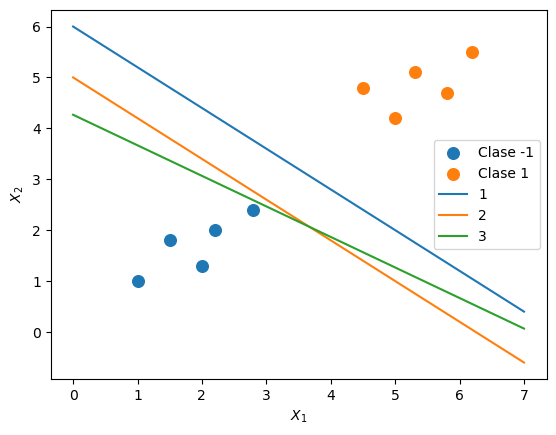

In [4]:
plt.figure()
for clase in np.unique(y):
    plt.scatter(
        X[y==clase, 0], X[y==clase, 1], label = f"Clase {clase}", s =70
    )

plt.plot(x,y1,label = "1")
plt.plot(x,y2, label = "2")
plt.plot(x,y3, label = "3")

plt.xlabel("$X_1$")
plt.ylabel('$X_2$')
plt.legend()
plt.show()

In [5]:
modelo = SVC(kernel = "linear", C = 1e6)
modelo.fit(X,y)

SVC(C=1000000.0, kernel='linear')

In [6]:
y_pred = modelo.predict(X)
accuracy_score(y,y_pred)
modelo.coef_
modelo.intercept_

array([-3.59505786])

In [7]:
decision = modelo.decision_function(X)
decision

array([-2.60397089, -1.97336214, -1.92803617, -1.50471002, -1.00010133,
        0.9998988 ,  1.00020301,  1.56765962,  1.65800733,  2.23452914])

In [8]:
def graficar_svm_lineal(modelo, X, y, titulo="Clasificador lineal"):
    
    plt.figure(figsize=(8, 6))
    
    for clase in np.unique(y):
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=70
        )
    
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    xx = np.linspace(x_min, x_max, 300)
    yy = np.linspace(y_min, y_max, 300)
    
    YY, XX = np.meshgrid(yy, xx)
    
    grid = np.c_[XX.ravel(), YY.ravel()]
    Z = modelo.decision_function(grid)
    Z = Z.reshape(XX.shape)
    
    plt.contour(
        XX,
        YY,
        Z,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"]
    )
    
    plt.scatter(
        modelo.support_vectors_[:, 0],
        modelo.support_vectors_[:, 1],
        s=180,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Vectores de soporte"
    )
    
    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()

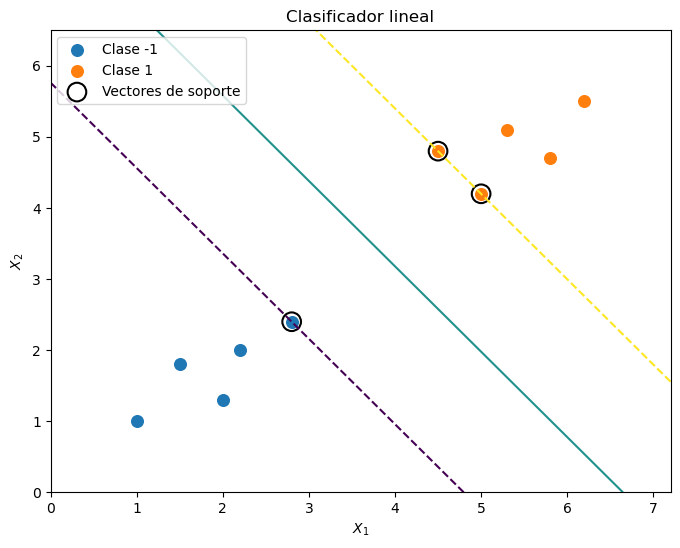

array([[2.8, 2.4],
       [4.5, 4.8],
       [5. , 4.2]])

In [9]:
graficar_svm_lineal(modelo,X,y)
modelo.support_vectors_

In [10]:
modelo.n_support_

array([1, 2], dtype=int32)

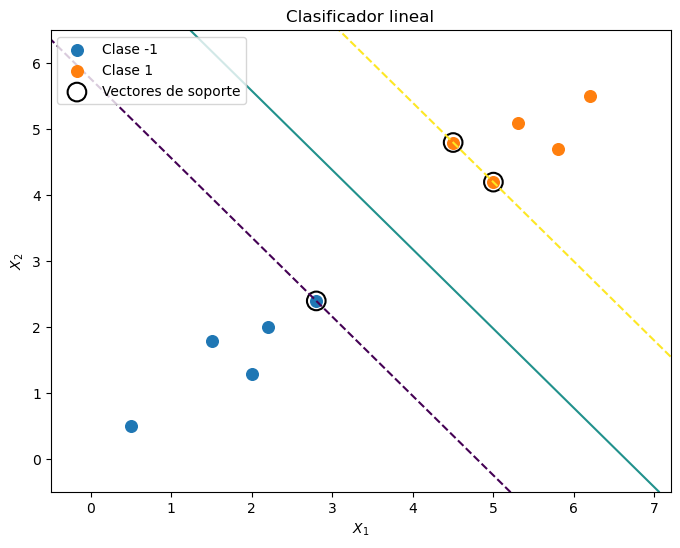

[[0.54086945 0.45021752]] [-3.59505786]
[[0.54086945 0.45021752]] [-3.59505786]


In [11]:
X_modificado = X.copy()
X_modificado[0] = [0.5,0.5]
modelo_modificado = SVC(kernel = "linear", C =1e6)
modelo_modificado.fit(X_modificado,y)
graficar_svm_lineal(modelo_modificado,X_modificado,y)
print(modelo.coef_,modelo.intercept_)
print(modelo_modificado.coef_,modelo_modificado.intercept_)

4


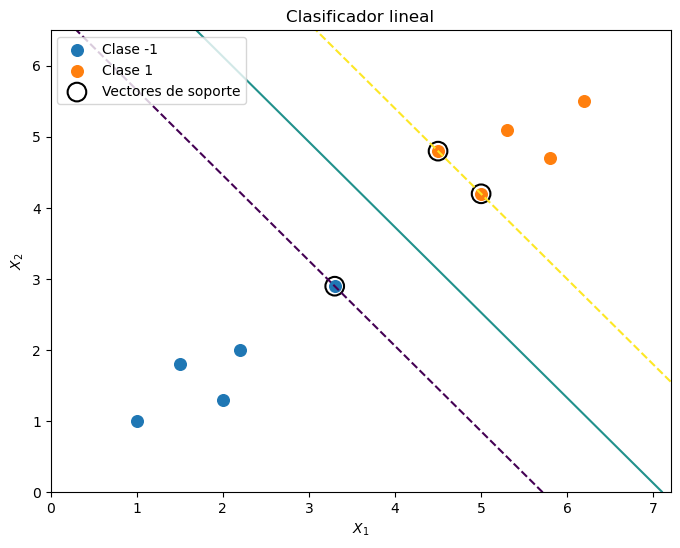

[[0.54086945 0.45021752]] [-3.59505786]
[[0.71884161 0.59862672]] [-5.10827679]


In [20]:
indice_soporte = modelo.support_[0]
print(indice_soporte)
X_soporte_modificado = X.copy()
X_soporte_modificado[indice_soporte] = (X_soporte_modificado[indice_soporte] + np.array([0.5,0.5]))
modelo_soporte_modificado = SVC(kernel = "linear", C = 1e6)
modelo_soporte_modificado.fit(X_soporte_modificado,y)
graficar_svm_lineal(modelo_soporte_modificado,X_soporte_modificado,y)
print(modelo.coef_,modelo.intercept_)
print(modelo_soporte_modificado.coef_,modelo_soporte_modificado.intercept_)

In [13]:
rng = np.random.default_rng(123)
X_neg = rng.normal(loc = [2,2], scale = 0.55, size=(50,2))
X_pos = rng.normal(loc = [5,5], scale = 0.55, size=(50,2))
X_grande = np.vstack([X_neg,X_pos])
y_grande = np.array([-1]*len(X_neg) + [1]*len(X_pos))

In [14]:
y_grande

array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [15]:
X_train,X_test,y_train,y_test = train_test_split(X_grande,y_grande, test_size = 0.30, random_state = 42, stratify = y_grande)
modelo_train = SVC(kernel = "linear", C = 1e6)
modelo_train.fit(X_train,y_train)


SVC(C=1000000.0, kernel='linear')

In [16]:
print(accuracy_score(y_train,modelo_train.predict(X_train)))
print(accuracy_score(y_test,modelo_train.predict(X_test)))

1.0
1.0


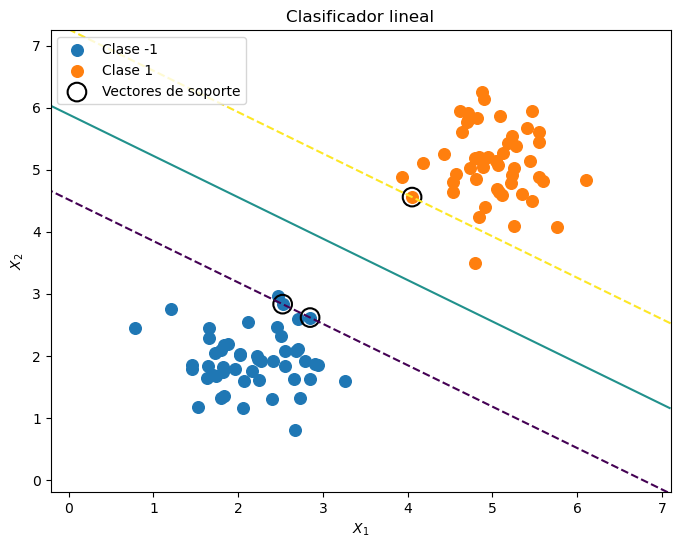

In [17]:
graficar_svm_lineal(modelo_train, X_grande,y_grande)

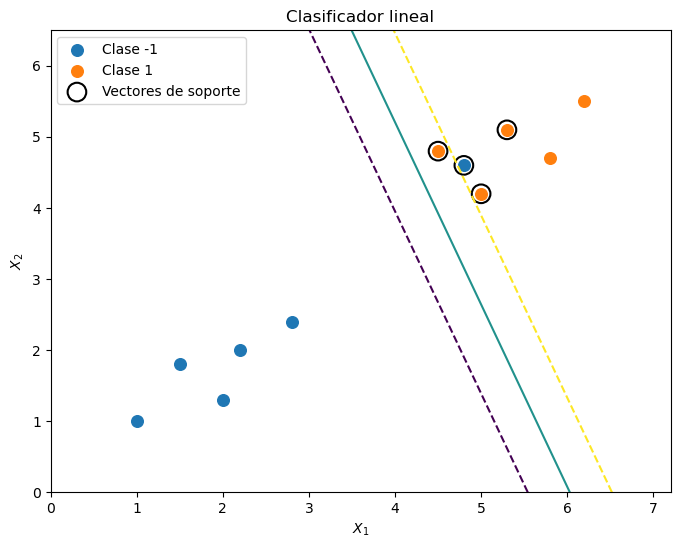

0.9090909090909091

In [18]:
X_no_separable = np.vstack([X,[4.8,4.6]])
y_no_separable = np.append(y,-1)
modelo_no_separable = SVC(kernel = "linear", C = 1e6)
modelo_no_separable.fit(X_no_separable,y_no_separable)
graficar_svm_lineal(modelo_no_separable,X_no_separable,y_no_separable)
accuracy_score(y_no_separable,modelo_no_separable.predict(X_no_separable))

# Ejercicios

## 12.15.1 Ejercicio 1
Utiliza el conjunto de datos original X y y.

Identifica:

los índices de los vectores de soporte;

las coordenadas de los vectores de soporte;

el número de vectores de soporte de cada clase.

Interpreta los resultados utilizando la gráfica.

Coordenadas de los vectores de soporte: [[2.8 2.4]
 [4.5 4.8]
 [5.  4.2]]
Numero de vectores de soporte:  [1 2]
indice de los vectores de soporte  [4 5 6]


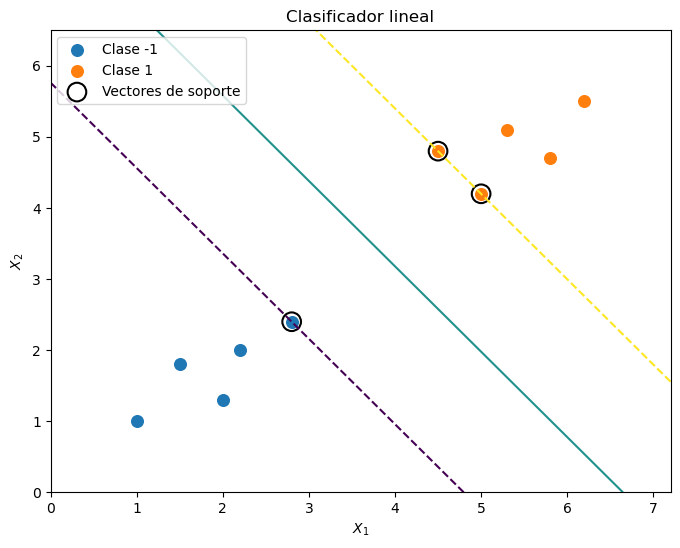

[[0.54086945 0.45021752]] [-3.59505786]


In [42]:
X = np.array([
    [1.0, 1.0],
    [1.5, 1.8],
    [2.0, 1.3],
    [2.2, 2.0],
    [2.8, 2.4],
    
    [4.5, 4.8],
    [5.0, 4.2],
    [5.3, 5.1],
    [5.8, 4.7],
    [6.2, 5.5]
])

y = np.array([-1, -1, -1, -1, -1,
               1,  1,  1,  1,  1])

datos = pd.DataFrame(X,columns = ["X1","X2"])
datos["Clases"] = y

modelo = SVC(kernel = "linear", C =1e6)
modelo.fit(X,y)

indx = modelo.support_
coordenadas = modelo.support_vectors_
numero = modelo.n_support_
print("Coordenadas de los vectores de soporte:", coordenadas)
print("Numero de vectores de soporte: ", numero)
print("indice de los vectores de soporte ", indx)
graficar_svm_lineal(modelo,X,y)
print(modelo.coef_,modelo.intercept_)

## 12.15.2 Ejercicio 2
Calcula manualmente el valor de la función de decisión para la primera observación:


Utiliza los valores almacenados en beta_0 y beta.

Después compara tu resultado con:

In [41]:

intercepto =modelo.intercept_[0]
b0 =modelo.coef_[0][0]
b1 = modelo.coef_[0][1]

def pred(x):
    pred = intercepto + b0*x[0] + b1*x[1]
    return pred

prediccion = pred([1.0, 1.0])
print("Predicción manual:", prediccion)
print("Predicción del modelo", modelo.decision_function(X)[0])


Predicción manual: -2.603970885000401
Predicción del modelo -2.6039708850004013


## Ejercicio 3
Selecciona una observación que no sea un vector de soporte y modifica ligeramente sus coordenadas.

Vuelve a ajustar el modelo y compara:

los coeficientes;

el término independiente;

los vectores de soporte;

la frontera de decisión.

¿Qué observas?
No cambia

Coordenadas de los vectores de soporte: [[2.8 2.4]
 [4.5 4.8]
 [5.  4.2]]
Numero de vectores de soporte:  [1 2]
indice de los vectores de soporte  [4 5 6]


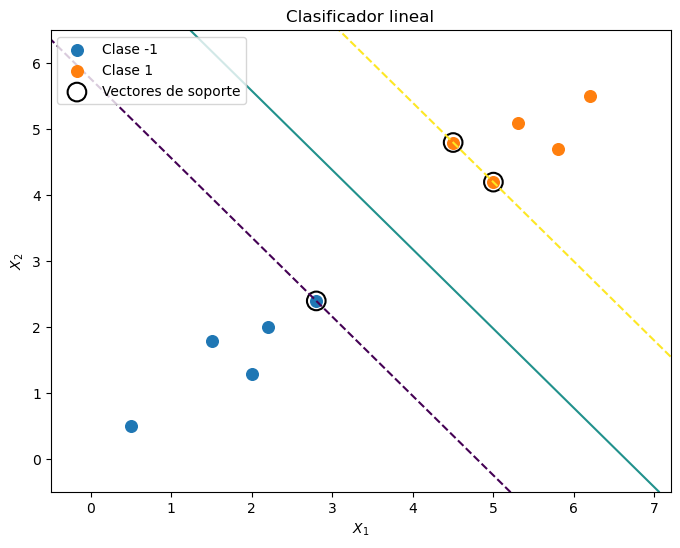

Coeficientes:  [[0.54086945 0.45021752]] [-3.59505786]
vectores de soporte [[2.8 2.4]
 [4.5 4.8]
 [5.  4.2]]


In [43]:
X_modificado = X.copy()
X_modificado[0] = [0.5,0.5]
modelo_modificado = SVC(kernel = "linear", C =1e6)
modelo_modificado.fit(X_modificado,y)
indx = modelo_modificado.support_
coordenadas = modelo_modificado.support_vectors_
numero = modelo_modificado.n_support_
print("Coordenadas de los vectores de soporte:", coordenadas)
print("Numero de vectores de soporte: ", numero)
print("indice de los vectores de soporte ", indx)
graficar_svm_lineal(modelo_modificado,X_modificado,y)
#print(modelo.coef_,modelo.intercept_)
print("Coeficientes: ",modelo_modificado.coef_,modelo_modificado.intercept_)
print("vectores de soporte", modelo_modificado.support_vectors_)